In [1]:
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from train import train

## Data Generation

In [2]:
def generate_sequences(n=128, variable_len=False, seed=13):
    """随机生成 n 组沿着正方形轮廓游走的坐标序列，每条序列随机选择起点、
    正向 / 反向绕行；可选固定长度或随机长度，叠加微小噪声；
    标签就是绕行方向，用来做序列分类训练。"""

    basic_corners = np.array([[-1, -1], [-1, 1], [1, 1], [1, -1]])
    # 创建独立随机数生成器
    rng = np.random.default_rng(seed)
    bases = rng.integers(4, size=n)
    if variable_len:
        # 3个可选值：0,1,2 → +2 → 2,3,4
        lengths = rng.integers(3, size=n) + 2
    else:
        lengths = [4] * n

    directions = rng.integers(2, size=n)

    points = [
        basic_corners[[(b + i) % 4 for i in range(4)]][slice(None, None, d * 2 - 1)][:l]
        + rng.standard_normal((l, 2)) * 0.1
        for b, d, l in zip(bases, directions, lengths)
    ]
    return np.array(points), np.array(directions)

In [3]:
points, directions = generate_sequences(n=128, seed=13)
test_points, test_directions = generate_sequences(seed=19)

In [4]:
train_data = TensorDataset(
    torch.as_tensor(points).float(), torch.as_tensor(directions).view(-1, 1).float()
)
test_data = TensorDataset(
    torch.as_tensor(test_points).float(),
    torch.as_tensor(test_directions).view(-1, 1).float(),
)
train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
test_loader = DataLoader(test_data, batch_size=16)

## Recurrent Neural Networks (RNNs)

+ 循环神经网络非常适合处理序列问题，因为它能够利用数据内在的结构，也就是数据点的先后顺序。
+ 依次输入循环神经网络的数据点如何改变RNN的内部（隐藏）状态，而该状态最终会成为整个序列的表征。
+ <font color="purple"> **循环神经网络的核心就是生成一个能够最好表示序列的隐藏状态** </font>
+ 隐状态本质上就是一个向量。向量的大小由你决定。
+ 你需要指定隐藏维度的数量，也就是设定用来表示隐状态的向量的大小。

## 基本结构

![](../pictures/7-30.png)

### 1. 有一个初始的<font color="purple">**隐藏状态h~i~表示空序列的状态**</font>，通常用0初始化。RNN单元需要两个输入，一个隐藏的状态代表到目前为止的序列状态，另一个是从输入序列按顺序依次输入的数据点。

### 2. 图中假设输入序列中有2个数据点。初始隐藏状态h0和输入序列的第一个数据x0这两个输入被用来生成一个新的隐藏状态（第一个数据点的h0），表示现在的更新状态。

### 3. 然后将输入数据中的第二个数据点x1和上一个的隐藏状态h0作为下一次的输入。新的隐藏状态既是当前步骤的输出，也是下一个步骤的输入之一。

### 4. 如果序列中还有另一个数据点，就一直执行此循环，直到处理完最后一个数据。最后一个隐藏的状态（在图中是h2）也是整个RNN的最终隐藏状态hf。

> ### 特别要注意的是，在多层神经网络中，如前面的CNN，每一层都有自己参数，自己的卷积核等。但是对于RNN来说，<font color="purple">**其实总体看只有一个层，数据被反复的输入到了这个层**</font>。在RNN中，h和x的输入经过变换后相加，最后由tanh函数激活后输出：

### $$ t_{h} = w_{hh}*h_{t - 1} + b_{hh} $$
### $$ t_{x} = w_{ih}*x_{t - 1} + b_{ih} $$
### $$ h_{t} = tanh(t_{h} + t_{x}) $$

> ### 此处需要注意的是，由于在最后一步中th和tx需要相加，因此<font color="purple">**需要这两个向量的维度是一样的才能相加**</font>。
> ### 注意道激活函数没有选用我们喜欢的ReLU函数，而是选择了tanh，主要是tanh能保证变换后的结果在-1和1之间。这使得下一次的数据输入更加可控，当然选择别的激活函数也是可以的。


## Pytorch的RNN层

### PyTorch提供了对应循环神经网络的nn.RNN层。RNN层负责处理隐藏状态，无论输入序列有多长，这也是实际计算模型中使用的层。我们已经了解RNN的内部工作原理，但Pytorch的RNN提供了更多的选项（例如堆叠和/或双向层），以及关于输入和输出形状的处理。

In [ ]:
# n_features = 2
# hidden_dim = 6
# torch.manual_seed(19)
# rnn = nn.RNN(input_size=n_features, hidden_size=hidden_dim, batch_first=True)


In [5]:
class SquareModel(nn.Module):
    def __init__(self, n_features, hidden_dim, n_outputs):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.n_features = n_features
        self.n_outputs = n_outputs
        self.hidden = None
        # Simple RNN
        self.basic_rnn = nn.RNN(self.n_features, self.hidden_dim, batch_first=True)
        # Classifier to produce as many logits as outputs
        self.classifier = nn.Linear(self.hidden_dim, self.n_outputs)

    def forward(self, X):
        # X is batch first (N, L, F)
        # output is (N, L, H)
        # final hidden state is (1, N, H)
        batch_first_output, self.hidden = self.basic_rnn(X)
        # only last item in sequence (N, 1, H)
        last_output = batch_first_output[:, -1]
        # classifier will output (N, 1, n_outputs)
        out = self.classifier(last_output)
        # final output is (N, n_outputs)
        return out.view(-1, self.n_outputs)

In [6]:
n_features = 2
hidden_dim = 2
n_outputs = 1
epochs = 100
model = SquareModel(n_features=n_features, hidden_dim=hidden_dim, n_outputs=n_outputs)
loss = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [7]:
train_losses, test_losses = train(
    model, train_loader, test_loader, loss, optimizer, epochs
)

Epoch 1/100 - loss: 0.6947 - val_loss: 0.6970
Epoch 2/100 - loss: 0.6886 - val_loss: 0.6914
Epoch 3/100 - loss: 0.6830 - val_loss: 0.6897
Epoch 4/100 - loss: 0.6792 - val_loss: 0.6885
Epoch 5/100 - loss: 0.6757 - val_loss: 0.6876
Epoch 6/100 - loss: 0.6711 - val_loss: 0.6857
Epoch 7/100 - loss: 0.6646 - val_loss: 0.6814
Epoch 8/100 - loss: 0.6566 - val_loss: 0.6756
Epoch 9/100 - loss: 0.6467 - val_loss: 0.6662
Epoch 10/100 - loss: 0.6347 - val_loss: 0.6539
Epoch 11/100 - loss: 0.6202 - val_loss: 0.6390
Epoch 12/100 - loss: 0.6029 - val_loss: 0.6205
Epoch 13/100 - loss: 0.5828 - val_loss: 0.6004
Epoch 14/100 - loss: 0.5634 - val_loss: 0.5802
Epoch 15/100 - loss: 0.5424 - val_loss: 0.5592
Epoch 16/100 - loss: 0.5209 - val_loss: 0.5373
Epoch 17/100 - loss: 0.4994 - val_loss: 0.5129
Epoch 18/100 - loss: 0.4784 - val_loss: 0.4855
Epoch 19/100 - loss: 0.4534 - val_loss: 0.4590
Epoch 20/100 - loss: 0.4276 - val_loss: 0.4292
Epoch 21/100 - loss: 0.4016 - val_loss: 0.3968
Epoch 22/100 - loss: 0

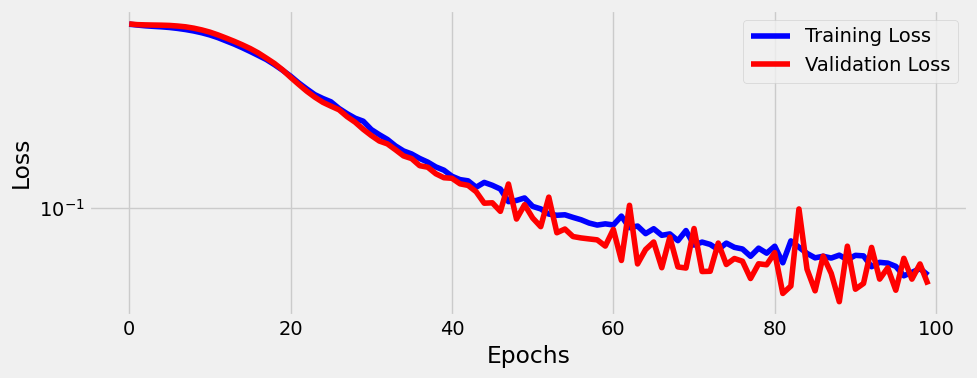

In [8]:
import matplotlib.pyplot as plt

plt.style.use("fivethirtyeight")


def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label="Training Loss", c="b")
    plt.plot(test_losses, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()


In [9]:
import torchmetrics

accuracy = torchmetrics.Accuracy(task="binary")
for _, (x, y) in enumerate(test_loader):
    yhat = model(x)
    accuracy(yhat, y)
accuracy.compute()
print(f"Test Accuracy: {accuracy.compute().item() * 100:.2f}%")


Test Accuracy: 98.44%
